# Tentativo 17 · Il modello come terzo annotatore

**La domanda.** Dal solo testo dei suoi articoli si può giudicare l'affidabilità di una testata, come fanno gli esperti?
I criteri di NewsGuard e di Media Bias/Fact Check (MBFC) guardano cose che un modello non vede (le fonti, le correzioni,
chi possiede il sito). La scommessa è che l'affidabilità lasci comunque un'impronta, una specie di **DNA**, in ogni
articolo.

**Il disegno.** Tre annotatori danno un giudizio sulle stesse testate:
- **NewsGuard**: il punteggio complessivo, in 5 livelli (l1–l5); affidabile = almeno 60 (l3–l5);
- **MBFC**: la fattualità ("factual reporting", da Very Low a Very High), in 5 livelli; affidabile = almeno "Mostly Factual";
- **il modello**: legge gli articoli della testata, dà un livello a ognuno, e la testata prende il livello votato dalla
  maggioranza; affidabile = la maggioranza degli articoli è almeno l3.

Si misura quanto vanno d'accordo, a coppie, con due misure standard: la **correlazione di Spearman** tra i livelli e la
**kappa di Cohen** su affidabile sì/no (l'accordo corretto per il caso: 0 = a caso, 1 = sempre d'accordo). Il punto di
riferimento è l'accordo tra i **due esperti**, NewsGuard e MBFC.

**Perché è pulito.**
- Non si addestra niente: le previsioni sono quelle del tentativo 16, e ogni testata è stata giudicata da un modello che
  non l'aveva mai vista (era nel fold di test).
- MBFC non è mai stato usato per addestrare: il confronto con MBFC è del tutto indipendente.
- Soglie, misure e modelli sono fissati qui, prima di guardare i risultati.
- I modelli sono quattro, uno per famiglia: TF-IDF, ModernBERT addestrato, Qwen3-Embedding 8B congelato, Mistral-Small 24B
  congelato (strato 27); ognuno come classificatore a 5 classi e come regressore sul punteggio.

In [1]:
T16_DIR = "../16_DataPreparation"          # il tentativo 16: dataset, fold e previsioni dei modelli
B = 2000                                    # ricampionamenti bootstrap per gli intervalli al 95%
R = 200                                     # ripetizioni per ogni numero di articoli nella curva del punto 3

In [2]:
# Parameters
T16_DIR = "/home/fabio.pinelli/John/Tentativo16"


In [3]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

T16 = Path(T16_DIR).expanduser(); sys.path.insert(0, str(T16))
import funzioni as F                        # le funzioni del tentativo 16 (dove sono i dati)
import accordo as A

warnings.filterwarnings("ignore")
OUT = Path("Results"); OUT.mkdir(exist_ok=True)
BLU, ARANCIO, GRIGIO, CHIARO = "#2a78d6", "#eb6834", "#52514e", "#b5b3ab"
plt.rcParams.update(F.STILE_GRAFICI)
t = pd.read_csv(F.DATASET / "testate.csv", index_col="domain")
mb = A.leggi_mbfc(F.DATI / "tentativi" / "10_EtichetteMBFC" / "mbfc_pulito.csv", t)
TESTATE = mb.index
ng = t.loc[TESTATE]
print(f"testate del tentativo 16: {len(t)}; valutate anche da MBFC (stesso dominio): {len(TESTATE)}")
print("livelli NewsGuard di queste testate:", ng.livello.value_counts().sort_index().to_dict())

testate del tentativo 16: 226; valutate anche da MBFC (stesso dominio): 170
livelli NewsGuard di queste testate: {'l1': 22, 'l2': 30, 'l3': 21, 'l4': 62, 'l5': 35}


## 1. I due esperti

Le 170 testate valutate da tutti e due. La tabella incrocia il livello NewsGuard con la fattualità MBFC: se i due
esperti fossero sempre d'accordo, i numeri starebbero sulla diagonale. Sotto, il loro accordo e il confronto con la
credibilità MBFC (che oltre alla fattualità tiene conto anche dell'orientamento politico e del traffico del sito: per
questo la misura principale è la fattualità).

In [4]:
ordine = ["Very Low", "Low", "Mixed", "Mostly Factual", "High", "Very High"]
display(pd.crosstab(ng.livello, pd.Categorical(mb.factual, ordine, ordered=True), rownames=["NewsGuard"], colnames=["MBFC fattualità"]))
NG_LV, NG_AFF = ng.label.to_numpy(), (ng.label >= A.SOGLIA["NewsGuard"]).astype(int).to_numpy()
MB_LV, MB_AFF = mb.fattualita.to_numpy(), (mb.fattualita >= A.SOGLIA["MBFC"]).astype(int).to_numpy()
CR_LV, CR_AFF = mb.credibilita_livello.to_numpy(), (mb.credibilita_livello >= A.SOGLIA["MBFC credibilità"]).astype(int).to_numpy()
pd.DataFrame({"NewsGuard ↔ MBFC fattualità": A.misure(NG_LV, MB_LV, NG_AFF, MB_AFF),
              "NewsGuard ↔ MBFC credibilità": A.misure(NG_LV, CR_LV, NG_AFF, CR_AFF)}).T.round(3)

MBFC fattualità,Very Low,Low,Mixed,Mostly Factual,High,Very High
NewsGuard,,,,,,
l1,1,9,11,1,0,0
l2,0,7,22,0,1,0
l3,0,2,10,5,4,0
l4,0,0,17,24,21,0
l5,0,0,4,5,25,1


,Spearman,kappa,accordo
NewsGuard ↔ MBFC fattualità,0.701,0.584,0.794
NewsGuard ↔ MBFC credibilità,0.697,0.489,0.735


## 2. L'accordo dei modelli, con tutti gli articoli

Per ogni modello e impostazione: l'accordo con NewsGuard e con MBFC, accanto a quello tra i due esperti. Le ultime due
colonne rispondono alla domanda del tentativo:
- **Δ con NewsGuard**: il modello è vicino a NewsGuard quanto lo è MBFC? (modello↔NewsGuard − MBFC↔NewsGuard)
- **Δ con MBFC**: il modello è vicino a MBFC quanto lo è NewsGuard? (modello↔MBFC − NewsGuard↔MBFC)

Zero vuol dire "come un esperto"; tra parentesi l'intervallo al 95% (bootstrap sulle testate, appaiato).

In [5]:
R16 = T16 / "Results"
mbert = [pd.read_csv(R16 / "modernbert" / c / f"fold{k}.csv") for c in ["5 classi", "regressione"] for k in range(1, 6)]
MODELLI = {"TF-IDF": pd.read_csv(R16 / "feature" / "previsioni_articoli.csv"),
           "ModernBERT": pd.concat(mbert[:5]).merge(pd.concat(mbert[5:])[["article_id", "s_regressione"]], on="article_id"),
           "Qwen3-Embedding 8B": pd.read_csv(R16 / "analisi_embedding" / "articoli_previsioni.csv"),
           "Mistral-Small 24B": pd.read_csv(R16 / "analisi_embedding" / "mistral27_articoli_previsioni.csv")}
GRUPPI = {}                                          # (modello, impostazione) → i livelli degli articoli di ogni testata
for m, pa in MODELLI.items():
    lv = A.livelli_articoli(pa, t).set_index("domain")
    for imp in ["classificatore", "regressore"]:
        GRUPPI[(m, imp)] = A.gruppi(lv[imp], TESTATE)
GIUDIZI = {k: A.giudizio(g) for k, g in GRUPPI.items()}

coppie = {("esperti", "", "NewsGuard ↔ MBFC"): (NG_LV, MB_LV, NG_AFF, MB_AFF)}
for (m, imp), (lv, aff) in GIUDIZI.items():
    coppie[(m, imp, "↔ NewsGuard")] = (lv, NG_LV, aff, NG_AFF)
    coppie[(m, imp, "↔ MBFC")] = (lv, MB_LV, aff, MB_AFF)
valori, campioni = A.bootstrap(coppie, len(TESTATE), B)
umano = campioni[("esperti", "", "NewsGuard ↔ MBFC")]


def cella(v, c):
    lo, hi = np.percentile(c, [2.5, 97.5]); return f"{v:.2f} [{lo:.2f}; {hi:.2f}]"


righe = {}
for (m, imp) in GIUDIZI:
    r = {}
    for mis in ["Spearman", "kappa"]:
        for rif in ["↔ NewsGuard", "↔ MBFC"]:
            r[f"{mis} {rif}"] = cella(valori[(m, imp, rif)][mis], campioni[(m, imp, rif)][mis])
            d = campioni[(m, imp, rif)][mis] - umano[mis]
            r[f"Δ {mis} {'con NewsGuard' if 'News' in rif else 'con MBFC'}"] = cella(valori[(m, imp, rif)][mis] - valori[("esperti", "", "NewsGuard ↔ MBFC")][mis], d)
    righe[(m, imp)] = r
tabella = pd.DataFrame(righe).T
tabella.to_csv(OUT / "accordo.csv")
print("esperti, NewsGuard ↔ MBFC:", {k: cella(v, umano[k]) for k, v in valori[("esperti", "", "NewsGuard ↔ MBFC")].items()})
tabella

esperti, NewsGuard ↔ MBFC: {'Spearman': '0.70 [0.61; 0.77]', 'kappa': '0.58 [0.47; 0.70]', 'accordo': '0.79 [0.74; 0.85]'}


Spearman ↔ NewsGuard  \
TF-IDF             classificatore    0.50 [0.38; 0.63]   
                   regressore        0.54 [0.43; 0.63]   
ModernBERT         classificatore    0.40 [0.26; 0.52]   
                   regressore        0.56 [0.45; 0.66]   
Qwen3-Embedding 8B classificatore    0.69 [0.59; 0.77]   
                   regressore        0.64 [0.56; 0.71]   
Mistral-Small 24B  classificatore    0.71 [0.61; 0.78]   
                   regressore        0.67 [0.59; 0.74]   

                                  Δ Spearman con NewsGuard    Spearman ↔ MBFC  \
TF-IDF             classificatore     -0.20 [-0.33; -0.06]  0.46 [0.34; 0.58]   
                   regressore         -0.16 [-0.28; -0.05]  0.51 [0.41; 0.61]   
ModernBERT         classificatore     -0.30 [-0.45; -0.16]  0.40 [0.27; 0.52]   
                   regressore         -0.14 [-0.25; -0.03]  0.53 [0.41; 0.63]   
Qwen3-Embedding 8B classificatore      -0.01 [-0.10; 0.08]  0.60 [0.50; 0.69]   
                   regressore          -0.06 [-0.15; 0.03]  0.61 [0.51; 0.69]   
Mistral-Small 24B  classificatore       0.01 [-0.09; 0.10]  0.60 [0.49; 0.68]   
                   regressore          -0.03 [-0.13; 0.07]  0.60 [0.51; 0.69]   

                                    Δ Spearman con MBFC  kappa ↔ NewsGuard  \
TF-IDF             classificatore  -0.24 [-0.35; -0.12]  0.50 [0.35; 0.64]   
                   regressore      -0.19 [-0.30; -0.07]  0.44 [0.29; 0.59]   
ModernBERT         classificatore  -0.30 [-0.44; -0.17]  0.36 [0.21; 0.51]   
                   regressore      -0.17 [-0.30; -0.06]  0.54 [0.39; 0.67]   
Qwen3-Embedding 8B classificatore  -0.10 [-0.19; -0.01]  0.59 [0.45; 0.70]   
                   regressore      -0.09 [-0.19; -0.00]  0.59 [0.46; 0.71]   
Mistral-Small 24B  classificatore  -0.11 [-0.19; -0.02]  0.64 [0.51; 0.76]   
                   regressore      -0.10 [-0.18; -0.01]  0.62 [0.48; 0.73]   

                                  Δ kappa con NewsGuard       kappa ↔ MBFC  \
TF-IDF             classificatore   -0.08 [-0.25; 0.08]  0.41 [0.28; 0.53]   
                   regressore       -0.14 [-0.31; 0.02]  0.39 [0.27; 0.52]   
ModernBERT         classificatore  -0.22 [-0.40; -0.05]  0.27 [0.15; 0.40]   
                   regressore       -0.04 [-0.21; 0.11]  0.41 [0.28; 0.54]   
Qwen3-Embedding 8B classificatore    0.00 [-0.15; 0.14]  0.48 [0.35; 0.61]   
                   regressore        0.01 [-0.15; 0.16]  0.48 [0.36; 0.60]   
Mistral-Small 24B  classificatore    0.06 [-0.10; 0.20]  0.47 [0.34; 0.58]   
                   regressore        0.04 [-0.11; 0.17]  0.54 [0.42; 0.65]   

                                       Δ kappa con MBFC  
TF-IDF             classificatore  -0.18 [-0.32; -0.05]  
                   regressore      -0.19 [-0.34; -0.05]  
ModernBERT         classificatore  -0.31 [-0.46; -0.17]  
                   regressore      -0.18 [-0.31; -0.05]  
Qwen3-Embedding 8B classificatore   -0.11 [-0.24; 0.01]  
                   regressore       -0.11 [-0.24; 0.01]  
Mistral-Small 24B  classificatore   -0.12 [-0.24; 0.00]  
                   regressore       -0.05 [-0.18; 0.08]

## 3. Il DNA: quanti articoli servono?

La stessa misura, ma il modello giudica la testata leggendo solo **k articoli presi a caso** (1, 3, 5, 9, 15, 25 o tutti),
con il voto di maggioranza: con k = 1 è il giudizio di **un solo articolo**. Ogni punto è la media di 200 estrazioni. La
fascia grigia è l'accordo tra i due esperti (con il suo intervallo al 95%).

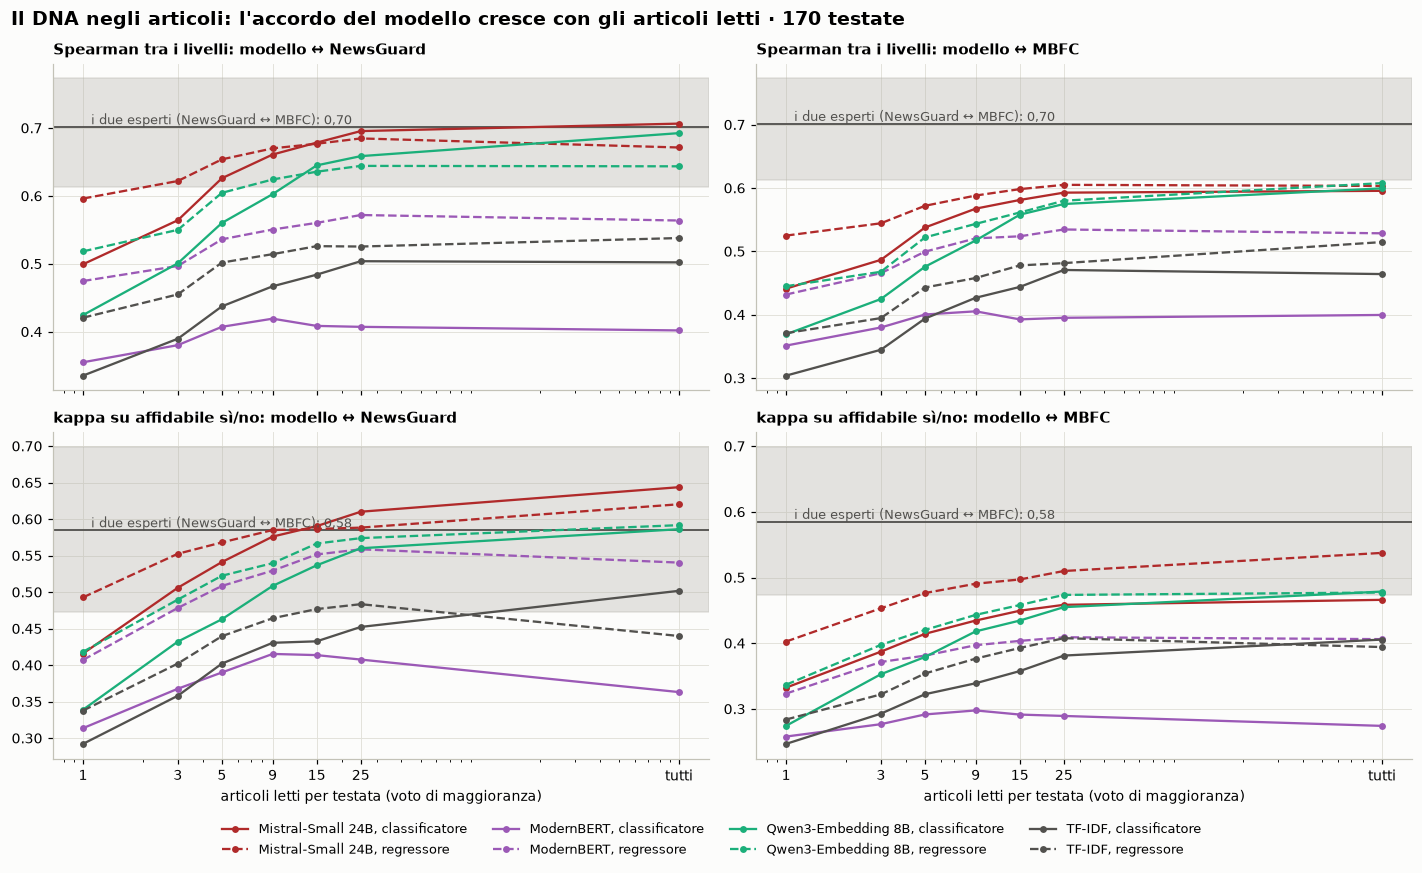

In [6]:
K = [1, 3, 5, 9, 15, 25, None]
rng = np.random.default_rng(0)
curva = []
for (m, imp), g in GRUPPI.items():
    for k in K:
        ripetizioni = R if k is not None else 1
        for _ in range(ripetizioni):
            lv, aff = A.giudizio(g, k, rng)
            for rif, (a, a_aff) in {"↔ NewsGuard": (NG_LV, NG_AFF), "↔ MBFC": (MB_LV, MB_AFF)}.items():
                curva.append({"modello": m, "impostazione": imp, "k": k or 999, "riferimento": rif, **A.misure(lv, a, aff, a_aff)})
curva = pd.DataFrame(curva).groupby(["modello", "impostazione", "riferimento", "k"])[["Spearman", "kappa", "accordo"]].mean().reset_index()
curva.to_csv(OUT / "curva_articoli.csv", index=False)

COLORI = {"TF-IDF": GRIGIO, "ModernBERT": "#9b59b6", "Qwen3-Embedding 8B": "#1baf7a", "Mistral-Small 24B": "#b02a2a"}   # non blu/arancio: lì vogliono dire NewsGuard/MBFC
fig, assi = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True)
for r, mis in enumerate(["Spearman", "kappa"]):
    lo, hi = np.percentile(umano[mis], [2.5, 97.5]); v = valori[("esperti", "", "NewsGuard ↔ MBFC")][mis]
    for c, rif in enumerate(["↔ NewsGuard", "↔ MBFC"]):
        ax = assi[r, c]
        ax.axhspan(lo, hi, color=CHIARO, alpha=0.35); ax.axhline(v, color=GRIGIO, lw=1.2)
        ax.text(1, v, f"  i due esperti (NewsGuard ↔ MBFC): {v:.2f}".replace(".", ","), va="bottom", fontsize=8.5, color=GRIGIO)
        for (m, imp), d in curva[curva.riferimento == rif].groupby(["modello", "impostazione"]):
            ax.plot(d.k, d[mis], marker="o", ms=3.5, color=COLORI[m], ls="-" if imp == "classificatore" else "--",
                    label=f"{m}, {imp}" if (r, c) == (0, 0) else None)
        ax.set_xscale("log"); ax.set_xticks([1, 3, 5, 9, 15, 25, 999], ["1", "3", "5", "9", "15", "25", "tutti"])
        ax.set_title(f"{'Spearman tra i livelli' if mis == 'Spearman' else 'kappa su affidabile sì/no'}: modello {rif}")
        if r == 1: ax.set_xlabel("articoli letti per testata (voto di maggioranza)")
fig.legend(loc="lower center", ncol=4, fontsize=8.5, bbox_to_anchor=(0.5, -0.06))
fig.suptitle(f"Il DNA negli articoli: l'accordo del modello cresce con gli articoli letti · {len(TESTATE)} testate",
             fontsize=12.5, fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.savefig(OUT / "curva_articoli.png", dpi=180, bbox_inches="tight"); plt.show()

## 4. Dove gli esperti non sono d'accordo

Le testate si dividono in due gruppi: quelle su cui NewsGuard e MBFC danno lo **stesso** giudizio affidabile sì/no, e
quelle su cui **non** sono d'accordo. Per ogni modello, quante volte il suo giudizio coincide con NewsGuard nei due gruppi.
Se il modello sbaglia soprattutto dove anche gli esperti litigano, i suoi errori stanno nei casi davvero incerti.

testate su cui i due esperti concordano: 135 su 170 (79%)


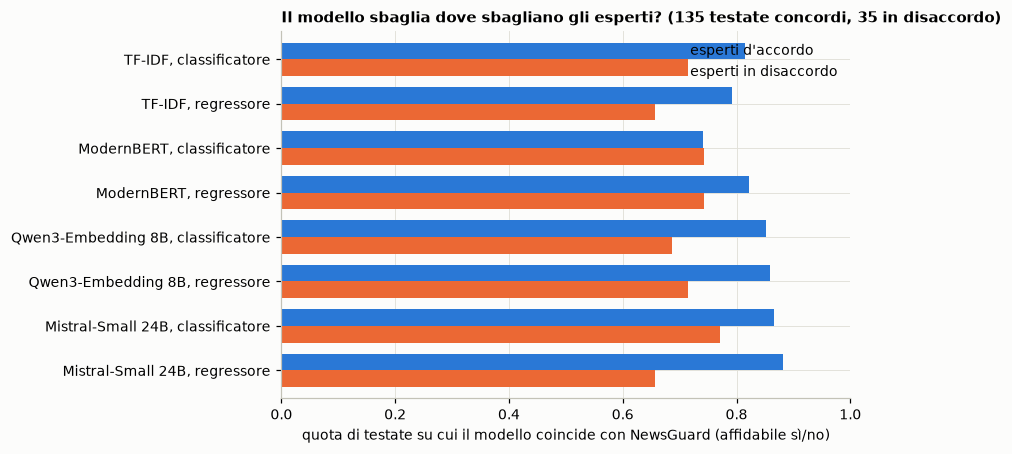

,esperti d'accordo,esperti in disaccordo
"TF-IDF, classificatore",0.81,0.71
"TF-IDF, regressore",0.79,0.66
"ModernBERT, classificatore",0.74,0.74
"ModernBERT, regressore",0.82,0.74
"Qwen3-Embedding 8B, classificatore",0.85,0.69
"Qwen3-Embedding 8B, regressore",0.86,0.71
"Mistral-Small 24B, classificatore",0.87,0.77
"Mistral-Small 24B, regressore",0.88,0.66


In [7]:
concordi = NG_AFF == MB_AFF
print(f"testate su cui i due esperti concordano: {concordi.sum()} su {len(concordi)} ({concordi.mean():.0%})")
dis = pd.DataFrame({f"{m}, {imp}": {"esperti d'accordo": (aff == NG_AFF)[concordi].mean(), "esperti in disaccordo": (aff == NG_AFF)[~concordi].mean()}
                    for (m, imp), (lv, aff) in GIUDIZI.items()}).T
dis.to_csv(OUT / "disaccordo.csv")
ax = dis.plot.barh(color=[BLU, ARANCIO], figsize=(8, 4.2), width=0.75)
ax.set_xlim(0, 1); ax.invert_yaxis(); ax.set_xlabel("quota di testate su cui il modello coincide con NewsGuard (affidabile sì/no)")
ax.set_title(f"Il modello sbaglia dove sbagliano gli esperti? ({concordi.sum()} testate concordi, {(~concordi).sum()} in disaccordo)")
plt.tight_layout(); plt.savefig(OUT / "disaccordo.png", dpi=180, bbox_inches="tight"); plt.show()
dis.round(2)

## 5. Controllo: la credibilità MBFC al posto della fattualità

Le stesse misure del punto 2 con la credibilità MBFC (bassa, media, alta; affidabile = alta). Se il quadro regge, il
risultato non dipende dalla scelta della misura MBFC.

In [8]:
controllo = {"esperti: NewsGuard ↔ MBFC credibilità": A.misure(NG_LV, CR_LV, NG_AFF, CR_AFF)}
for (m, imp), (lv, aff) in GIUDIZI.items():
    controllo[f"{m}, {imp} ↔ MBFC credibilità"] = A.misure(lv, CR_LV, aff, CR_AFF)
pd.DataFrame(controllo).T.round(3)

,Spearman,kappa,accordo
esperti: NewsGuard ↔ MBFC credibilità,0.697,0.489,0.735
"TF-IDF, classificatore ↔ MBFC credibilità",0.506,0.390,0.682
"TF-IDF, regressore ↔ MBFC credibilità",0.503,0.377,0.676
"ModernBERT, classificatore ↔ MBFC credibilità",0.447,0.291,0.629
"ModernBERT, regressore ↔ MBFC credibilità",0.512,0.365,0.671
"Qwen3-Embedding 8B, classificatore ↔ MBFC credibilità",0.588,0.451,0.718
"Qwen3-Embedding 8B, regressore ↔ MBFC credibilità",0.565,0.412,0.694
"Mistral-Small 24B, classificatore ↔ MBFC credibilità",0.592,0.443,0.712
"Mistral-Small 24B, regressore ↔ MBFC credibilità",0.577,0.487,0.735


## 6. Il quadro in un colpo d'occhio

Per ogni modello (classificatore e regressore, con tutti gli articoli e il voto di maggioranza): in blu l'accordo con
NewsGuard, in arancio con MBFC, linee grigie: intervalli al 95%. La fascia grigia verticale è l'accordo tra i due esperti.
Un modello che arriva alla fascia giudica le testate come un esperto in più.

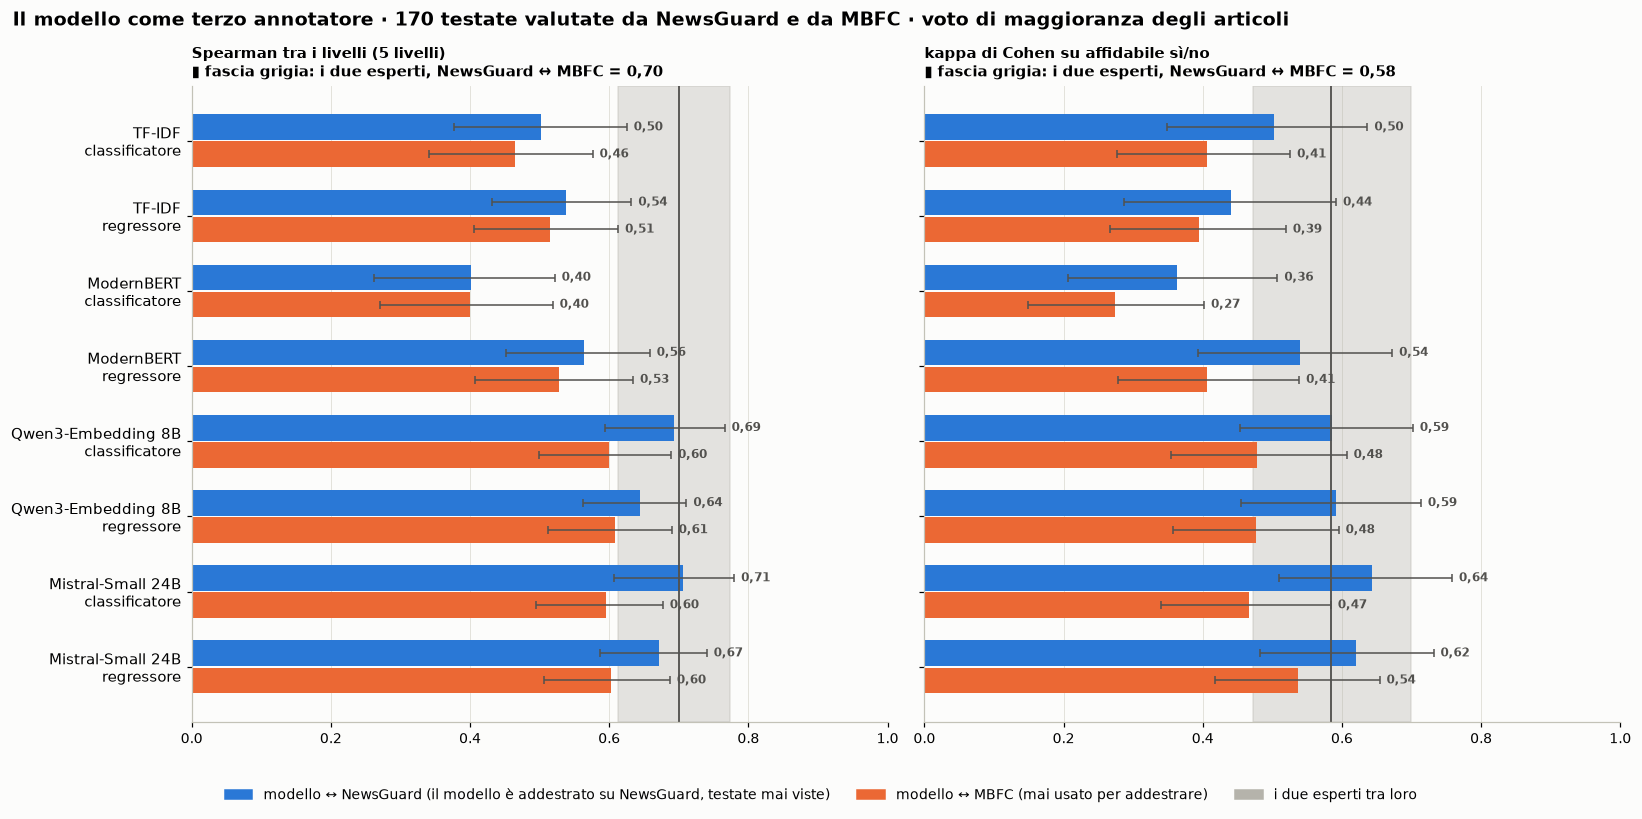

In [9]:
righe_g = list(GIUDIZI)
fig, assi = plt.subplots(1, 2, figsize=(15, 0.62 * len(righe_g) + 2), sharey=True)
y = np.arange(len(righe_g))[::-1]
for ax, mis, titolo in zip(assi, ["Spearman", "kappa"], ["Spearman tra i livelli (5 livelli)", "kappa di Cohen su affidabile sì/no"]):
    v = valori[("esperti", "", "NewsGuard ↔ MBFC")][mis]; lo, hi = np.percentile(umano[mis], [2.5, 97.5])
    ax.axvspan(lo, hi, color=CHIARO, alpha=0.35); ax.axvline(v, color=GRIGIO, lw=1.2)
    for dy, rif, colore in [(0.18, "↔ NewsGuard", BLU), (-0.18, "↔ MBFC", ARANCIO)]:
        for yy, k in zip(y, righe_g):
            x = valori[(*k, rif)][mis]; a, b = np.percentile(campioni[(*k, rif)][mis], [2.5, 97.5])
            ax.barh(yy + dy, x, height=0.34, color=colore)
            ax.errorbar(x, yy + dy, xerr=[[x - a], [b - x]], color=GRIGIO, lw=1, capsize=2.5)
            ax.text(b + 0.01, yy + dy, f"{x:.2f}".replace(".", ","), va="center", fontsize=8, color=GRIGIO, fontweight="bold")
    ax.set_xlim(0, 1); ax.grid(False); ax.grid(axis="x")
    ax.set_title(f"{titolo}\n▮ fascia grigia: i due esperti, NewsGuard ↔ MBFC = {v:.2f}".replace(".", ","), fontsize=10)
assi[0].set_yticks(y, [f"{m}\n{imp}" for m, imp in righe_g], fontsize=9.5)
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in [BLU, ARANCIO, CHIARO]],
           ["modello ↔ NewsGuard (il modello è addestrato su NewsGuard, testate mai viste)", "modello ↔ MBFC (mai usato per addestrare)",
            "i due esperti tra loro"], ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.07), fontsize=9)
fig.suptitle(f"Il modello come terzo annotatore · {len(TESTATE)} testate valutate da NewsGuard e da MBFC · voto di maggioranza degli articoli",
             fontsize=12.5, fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.savefig(OUT / "colpo_d_occhio.png", dpi=180, bbox_inches="tight"); plt.show()

## 7. Che cosa viene fuori

**I due esperti** sono d'accordo fino a un certo punto: Spearman 0,70 [0,61; 0,77], kappa 0,58 [0,47; 0,70], stesso
giudizio affidabile sì/no su 135 testate su 170 (79%). È il tetto naturale: due valutazioni umane di qualità.

**I modelli grandi congelati sono annotatori al livello degli esperti rispetto a NewsGuard.**
- Qwen3-Embedding 8B e Mistral-Small 24B, leggendo solo gli articoli, vanno d'accordo con NewsGuard **quanto MBFC**:
  Spearman 0,64–0,71 contro 0,70, kappa 0,59–0,64 contro 0,58; le differenze dall'accordo tra esperti stanno tra −0,06
  e +0,06 e i loro intervalli contengono lo zero.
- **Con MBFC, mai usato per addestrare**, l'accordo è un po' più basso di quello di NewsGuard (Spearman 0,60–0,61 contro
  0,70; kappa 0,47–0,54 contro 0,58), ma resta lontano dal caso; per il regressore di Mistral la kappa (0,54) sta dentro
  l'intervallo degli esperti. È il confronto più severo: il modello ha imparato le etichette di NewsGuard.
- TF-IDF e ModernBERT restano chiaramente sotto (da −0,14 a −0,30 dagli esperti).

**Il DNA è negli articoli, e si somma.** Un solo articolo dà già un accordo con NewsGuard ben sopra il caso (Spearman
0,42–0,60, kappa 0,34–0,49 per i modelli grandi); il voto di più articoli lo fa crescere, e con circa 9–25 articoli i
modelli grandi arrivano al livello dei due esperti.

**Gli errori stanno dove anche gli esperti litigano.** Sulle 135 testate su cui NewsGuard e MBFC concordano, i modelli
grandi coincidono con NewsGuard nell'85–88% dei casi; sulle 35 in disaccordo, nel 66–77%.

**Controllo.** Con la credibilità MBFC al posto della fattualità il quadro non cambia (esperti: kappa 0,49; regressore di
Mistral: 0,49).

**Limiti.** Le testate sono 170 (quelle con MBFC, il 75% delle 226), quindi gli intervalli sono larghi circa ±0,1; il
modello è addestrato su NewsGuard (su testate diverse), per questo il confronto indipendente è quello con MBFC.